jumlah klaster terbentuk : 2
banyaknya data noise     : 2


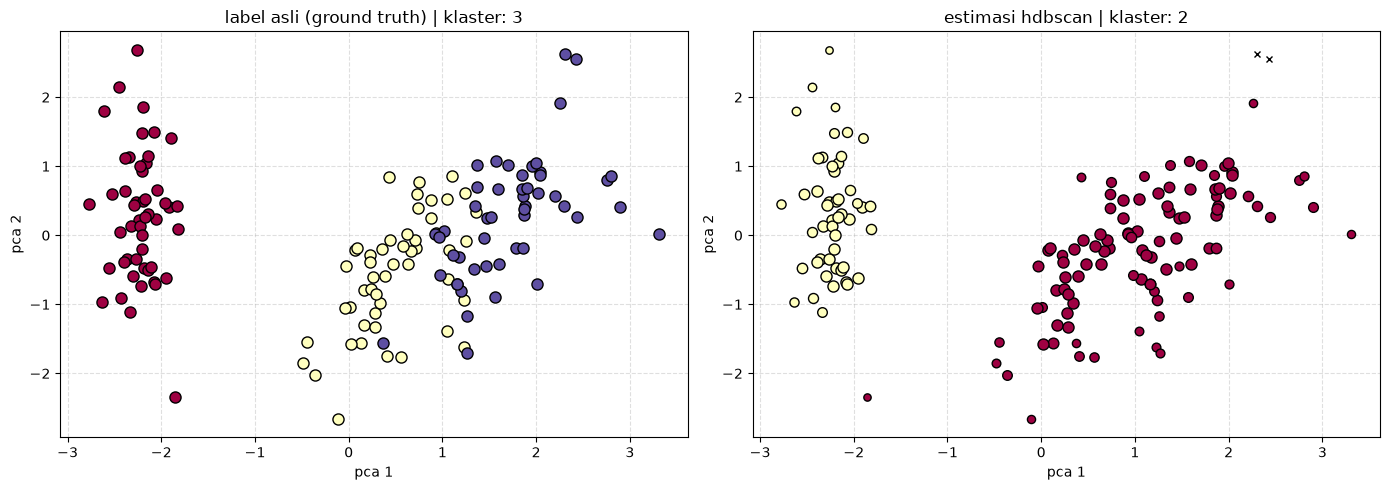

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import hdbscan

# memuat dataset bunga iris dari pustaka sklearn
iris = load_iris()
x_raw = iris.data
y_true = iris.target

# menyamakan skala seluruh fitur agar perhitungan jarak antar data adil
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x_raw)

# meringkas empat fitur data menjadi dua dimensi utama agar bisa digambar ke grafik
pca = PCA(n_components=2, random_state=42)
x_pca = pca.fit_transform(x_scaled)

# mengelompokkan data berdasarkan kerapatan kepadatan titik menggunakan hdbscan
clusterer = hdbscan.HDBSCAN(min_cluster_size=10, min_samples=5)
labels = clusterer.fit_predict(x_scaled)
probabilities = clusterer.probabilities_

# menghitung total kelompok yang terbentuk tanpa menghitung data noise
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)

# menghitung jumlah titik data yang dianggap terasing atau noise
n_noise = list(labels).count(-1)

# menampilkan ringkasan keluaran berupa angka ke layar
print(f"jumlah klaster terbentuk : {n_clusters}")
print(f"banyaknya data noise     : {n_noise}")

# fungsi menggambar grafik yang diadaptasi langsung dari kode praktikum satu
def plot(x, lbls, probs=None, ground_truth=False, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 5))
        
    unique_labels = set(lbls)
    colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
    proba_map = {idx: probs[idx] for idx in range(len(lbls))} if probs is not None else {}
    
    for k, col in zip(unique_labels, colors):
        # memberi warna hitam khusus untuk data yang dianggap noise
        if k == -1:
            col = [0, 0, 0, 1]
            
        class_index = (lbls == k).nonzero()[0]
        
        for ci in class_index:
            # menggambar tanda silang untuk noise dan lingkaran untuk anggota kelompok
            ax.plot(
                x[ci, 0],
                x[ci, 1],
                "x" if k == -1 else "o",
                markerfacecolor=tuple(col),
                markeredgecolor="k",
                markersize=5 if k == -1 else (4 + 4 * proba_map.get(ci, 1.0))
            )
            
    n_c = len(set(lbls)) - (1 if -1 in lbls else 0)
    preamble = "label asli (ground truth)" if ground_truth else "estimasi hdbscan"
    ax.set_title(f"{preamble} | klaster: {n_c}")
    ax.set_xlabel("pca 1")
    ax.set_ylabel("pca 2")
    ax.grid(True, linestyle="--", alpha=0.4)

# menyiapkan kanvas bersisian untuk membandingkan label asli dan hasil hdbscan
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# menggambar sebaran label asli bunga iris
plot(x_pca, y_true, ground_truth=True, ax=axes[0])

# menggambar hasil pengelompokan yang ditemukan oleh mesin hdbscan
plot(x_pca, labels, probs=probabilities, ground_truth=False, ax=axes[1])

# merapikan tata letak tampilan grafik lalu memunculkannya ke layar
plt.tight_layout()
plt.show()